# Lab 5: Introducing GeoAI
In the words of the developers themselves:
"GeoAI is a comprehensive Python package designed to bridge artificial intelligence (AI) and geospatial data analysis, providing researchers and practitioners with intuitive tools for applying machine learning techniques to geographic data. The package offers a unified framework for processing satellite imagery, aerial photographs, and vector data using state-of-the-art deep learning models. GeoAI integrates popular AI frameworks including PyTorch, Transformers, PyTorch Segmentation Models, and specialized geospatial libraries like torchange, enabling users to perform complex geospatial analyses with minimal code."
- [GeoAI 2025](https://opengeoai.org/)


The aim of the this lab is take the knowldege of fundamental mechanics in both satellite data and AI that you have this far gained- and apply them via the bridge that GeoAI provides.

This lab is a modified version of the following tutorial:
- [GeoAI Workshop 2025](https://www.youtube.com/watch?v=jdK-cleFUkc&ab_channel=OpenGeospatialSolutions)

A key thing to be aware of- we are stepping away here from using the GEE API, and taking a pure Python approach. So we have to go get our own data, and all our processing is happening on our 'local'.


# Task 1: mapping surface water with S2
We start by installing the required package and setting CoLab to run on a GPU. Until now, we have been running all our code on a CPU, a GPU allows us to use neural networks much more effectively.



To use GPU, please click the "Runtime" menu and select "Change runtime type". Then select "T4 GPU" from the dropdown menu. GPU acceleration is highly recommended for training deep learning models, as it can reduce training time from hours to minutes. It may already be set to this, but check!

If you are running this lab on your own laptop, follow the installation instructions linked below in order to ensure that GPU and subsequent CUDA usage is connected up correctly [people using Colab, no need to do so]:
- https://opengeoai.org/installation/
- https://aibook.gishub.org/book/foundations/setup/


First we will test to make sure our GPU is working in Colab. The cell below should produce something like:

```
PyTorch: 2.x.x
CUDA available: True
GPU: Tesla T4
```

If it does not, check that your runtime is set to a T4 GPU. If it is set to that and is still not using the CUDA and T4, restart the runtime.

In [ ]:
# Check Colab GPU
import torch

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    raise RuntimeError(
        "No CUDA GPU detected. Select Runtime > Change runtime type > T4 GPU."
    )

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Next we install Geo-AI:

In [ ]:
# Install GeoAI
%pip install -q geoai-py

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 651.5/651.5 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 669.2/669.2 kB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.3/46.3 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 70.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 812.4/812.4 kB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.6/21.6 MB 88.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8

And now we import and test that they are going to play nice together. The following should be the reported status:



```
GeoAI: 0.4x.x
PyTorch: 2.xx.x+cu128
CUDA available: True
CUDA version: 12.x
GPU: Tesla T4
GeoAI device: cuda
```



In [ ]:
# Import key libs and check function of them
import torch
import geoai

print("GeoAI:", geoai.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print(f"GPU:     {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: No CUDA GPU detected.")

GeoAI: 0.43.1
PyTorch: 2.11.0+cu130
CUDA available: True
CUDA version: 13.0
GPU:     Tesla T4


### Basemap configuration (run this before any map)

The interactive maps in this lab are built by `leafmap` on top of `ipyleaflet`.
Its default basemap is OpenStreetMap, and OSM's tile usage policy returns
**HTTP 403** to the Colab client, so the maps come back blank, grey or with a 403 tile error.

Passing a local GeoTIFF as `basemap=` does *not* fix this: your raster is added
as an extra layer, but the default OSM layer is still there underneath.

The cell below is a custom interactive display batch of code. Just run the code whenever you start a new session to have it available.

In [ ]:
# @title
# =====================================================================
# Local-data-only interactive map — no basemap, no tile server, no
# network calls except a one-time load of the Leaflet.js library itself
# from a CDN (that is a small JS/CSS file your browser fetches once,
# not a per-pan-and-zoom map-tile request, so it isn't subject to the
# same rate limits/blocks as OSM or Esri tiles).
#
# The map runs in Leaflet's CRS.Simple mode: there is no basemap layer
# of any kind, only the imagery/masks/vectors you hand it, drawn on a
# flat plane using the raster's own coordinate system (metres, for a
# projected CRS). Panning and zooming are native Leaflet — fully
# interactive, nothing pre-rendered.
#
# Usage:
#   show_interactive(raster=train_raster_path, vector=train_vector_path,
#                     title="Training scene")
#
#   show_interactive(raster=test_raster_path, mask=masks_path,
#                     probability=probability_path, title="Test predictions")
#
#   show_interactive(raster=test_raster_path, vector=gdf_filtered,
#                     vector_column="area_m2", title="Filtered detections")
# =====================================================================

import base64, io, json, uuid
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import rasterio
from rasterio.enums import Resampling
from IPython.display import HTML, display

try:
    import geopandas as gpd
except ImportError:
    gpd = None

_MAX_PX = 1600  # longest side of any image actually embedded in the page


def _read_scene(path, indexes, max_px=_MAX_PX):
    with rasterio.open(path) as src:
        h, w = src.height, src.width
        scale = min(1.0, max_px / max(h, w))
        out_h, out_w = max(1, round(h * scale)), max(1, round(w * scale))
        data = src.read(
            indexes=indexes, out_shape=(len(indexes), out_h, out_w),
            resampling=Resampling.bilinear, masked=True,
        )
        return data, src.bounds, src.crs


def _stretch(band, divider=None, pct=(2, 98)):
    band = band.astype("float32")
    if divider:
        s = band / float(divider)
    else:
        valid = np.ma.compressed(band)
        valid = valid[np.isfinite(valid)]
        if valid.size:
            lo, hi = np.percentile(valid, pct[0]), np.percentile(valid, pct[1])
        else:
            lo, hi = 0.0, 1.0
        if hi <= lo:
            hi = lo + 1e-6
        s = (band - lo) / (hi - lo)
    return np.clip(np.ma.filled(s, 0.0), 0.0, 1.0)


def _png_uri(rgba):
    buf = io.BytesIO()
    plt.imsave(buf, np.clip(rgba, 0.0, 1.0), format="png")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode("ascii")


def _raster_overlay(path, indexes=None, divider=None, pct=(2, 98), cmap="gray"):
    with rasterio.open(path) as src:
        n = src.count
    if indexes is None:
        indexes = [1, 2, 3] if n >= 3 else [1]
    data, bounds, crs = _read_scene(path, indexes)
    if len(indexes) >= 3:
        rgb = np.dstack([_stretch(data[i], divider, pct) for i in range(3)])
        mask = np.ma.getmaskarray(data)
        alpha = np.ones(rgb.shape[:2], "float32")
        if mask is not np.ma.nomask and mask.any():
            alpha = (~np.any(mask, axis=0)).astype("float32")
        rgba = np.dstack([rgb, alpha])
    else:
        band = _stretch(data[0], divider, pct)
        rgba = plt.get_cmap(cmap)(band)
        m = np.ma.getmaskarray(data[0])
        if m is not np.ma.nomask:
            rgba[..., 3] = np.where(m, 0.0, 1.0)
    return {"uri": _png_uri(rgba), "bounds": bounds, "crs": crs}


def _mask_overlay(path, nodata=0, color="red", alpha=0.55):
    data, bounds, crs = _read_scene(path, [1])
    band = data[0]
    hit = np.ma.filled(band, nodata) != nodata
    m = np.ma.getmaskarray(band)
    if m is not np.ma.nomask:
        hit &= ~m
    r, g, b = to_rgb(color)
    rgba = np.zeros(hit.shape + (4,), "float32")
    rgba[..., 0], rgba[..., 1], rgba[..., 2] = r, g, b
    rgba[..., 3] = hit.astype("float32") * alpha
    return {"uri": _png_uri(rgba), "bounds": bounds, "crs": crs}


def _probability_overlay(path, band=2, cmap="magma", alpha=0.75, min_display=0.0):
    data, bounds, crs = _read_scene(path, [band])
    p = data[0].astype("float32")
    finite = np.ma.compressed(p)
    if finite.size and np.nanmax(finite) > 1.5:  # stored as 0-255 or 0-100
        p = p / (255.0 if np.nanmax(finite) > 100.0 else 100.0)
    filled = np.ma.filled(p, 0.0)
    rgba = plt.get_cmap(cmap)(np.clip(filled, 0.0, 1.0))
    rgba[..., 3] = np.where(filled < min_display, 0.0, alpha)
    return {"uri": _png_uri(rgba), "bounds": bounds, "crs": crs}


def _jsonable(v):
    if isinstance(v, (np.floating,)):
        return round(float(v), 4)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, float):
        return round(v, 4)
    if isinstance(v, (int, str)):
        return v
    return None


def _vector_features(source, target_crs, column=None):
    if gpd is None:
        raise ImportError("geopandas is required to display a vector layer")
    gdf = source if hasattr(source, "geometry") else gpd.read_file(source)
    if target_crs is not None and gdf.crs is not None and gdf.crs != target_crs:
        gdf = gdf.to_crs(target_crs)

    values = None
    if column and column in gdf.columns:
        values = gdf[column].astype(float)
    vmin, vmax = (float(values.min()), float(values.max())) if values is not None and len(values) else (0.0, 1.0)
    cmap = plt.get_cmap("viridis")

    feats = []
    for i, (_, row) in enumerate(gdf.iterrows()):
        geom = row.geometry
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type == "Polygon":
            polys = [geom]
        elif geom.geom_type == "MultiPolygon":
            polys = list(geom.geoms)
        else:
            continue
        rings = [[[y, x] for x, y in poly.exterior.coords] for poly in polys]
        if not rings:
            continue
        color = "#3388ff"
        if values is not None:
            v = values.iloc[i]
            t = 0.5 if vmax <= vmin else (v - vmin) / (vmax - vmin)
            rc = cmap(t)
            color = "#%02x%02x%02x" % tuple(int(255 * c) for c in rc[:3])
        props = {}
        for k, v in row.drop(labels="geometry").items():
            jv = _jsonable(v)
            if jv is not None:
                props[k] = jv
        feats.append({"rings": rings, "color": color, "props": props})
    return feats


def show_interactive(
    raster=None, indexes=None, divider=None, pct=(2, 98), cmap="gray",
    mask=None, mask_nodata=0, mask_color="red", mask_alpha=0.55,
    probability=None, probability_band=2, probability_cmap="magma",
    probability_alpha=0.75, probability_min_display=0.0,
    vector=None, vector_column=None, vector_label=None,
    title=None, height=560,
):
    """Interactive pan/zoom map of local rasters and vectors. No basemap."""
    if raster is None and mask is None and probability is None:
        raise ValueError("Pass at least one of raster=, mask=, probability=")

    parts = []
    if raster is not None:
        parts.append(("Imagery", _raster_overlay(raster, indexes, divider, pct, cmap), True))
    if mask is not None:
        parts.append(("Prediction", _mask_overlay(mask, mask_nodata, mask_color, mask_alpha), True))
    if probability is not None:
        parts.append((
            "Probability",
            _probability_overlay(probability, probability_band, probability_cmap,
                                  probability_alpha, probability_min_display),
            False,
        ))

    ref_crs = next((r["crs"] for _, r, _ in parts if r["crs"] is not None), None)
    b0 = parts[0][1]["bounds"]
    west, south, east, north = b0.left, b0.bottom, b0.right, b0.top
    for _, r, _ in parts[1:]:
        b = r["bounds"]
        west, south = min(west, b.left), min(south, b.bottom)
        east, north = max(east, b.right), max(north, b.top)
    ox, oy = west, south

    def leaflet_bounds(b):
        return [[b.bottom - oy, b.left - ox], [b.top - oy, b.right - ox]]

    image_layers = [
        {"name": name, "url": r["uri"], "bounds": leaflet_bounds(r["bounds"]), "default_on": on}
        for name, r, on in parts
    ]

    vector_layer = None
    if vector is not None:
        feats = _vector_features(vector, ref_crs, vector_column)
        for f in feats:
            f["rings"] = [[[y - oy, x - ox] for y, x in ring] for ring in f["rings"]]
        vector_layer = {"name": vector_label or "Vector", "features": feats}

    div_id = "map_" + uuid.uuid4().hex[:10]
    payload = {
        "images": image_layers,
        "vector": vector_layer,
        "fit_bounds": [[0, 0], [north - oy, east - ox]],
        "title": title,
    }
    payload_json = json.dumps(payload).replace("</script", "<\\/script")

    html = f"""
<div id="{div_id}" style="height:{height}px;width:100%;border:1px solid #ccc;border-radius:4px;"></div>
<script>
(function() {{
  function ensureLeaflet(cb) {{
    if (window.L) {{ cb(); return; }}
    var css = document.createElement('link');
    css.rel = 'stylesheet';
    css.href = 'https://unpkg.com/leaflet@1.9.4/dist/leaflet.css';
    document.head.appendChild(css);
    var script = document.createElement('script');
    script.src = 'https://unpkg.com/leaflet@1.9.4/dist/leaflet.js';
    script.onload = cb;
    document.head.appendChild(script);
  }}

  function init() {{
    var data = {payload_json};
    var map = L.map('{div_id}', {{
      crs: L.CRS.Simple,
      minZoom: -10,
      maxZoom: 30,
      zoomSnap: 0.1,
      zoomDelta: 0.5,
      attributionControl: false,
    }});

    var overlays = {{}};
    data.images.forEach(function(img) {{
      var layer = L.imageOverlay(img.url, img.bounds, {{opacity: 1}});
      overlays[img.name] = layer;
      if (img.default_on) layer.addTo(map);
    }});

    if (data.vector) {{
      var group = L.layerGroup();
      data.vector.features.forEach(function(f) {{
        var poly = L.polygon(f.rings, {{color: f.color, weight: 1.5, fillOpacity: 0.25}});
        var keys = Object.keys(f.props);
        if (keys.length) {{
          var rows = keys.map(function(k) {{
            return '<tr><td style="padding-right:8px;color:#666;">' + k + '</td><td>' + f.props[k] + '</td></tr>';
          }}).join('');
          poly.bindPopup('<table>' + rows + '</table>');
        }}
        poly.addTo(group);
      }});
      overlays[data.vector.name] = group;
      group.addTo(map);
    }}

    if (Object.keys(overlays).length > 1) {{
      L.control.layers(null, overlays, {{collapsed: false}}).addTo(map);
    }}
    L.control.scale({{metric: true, imperial: false}}).addTo(map);
    map.fitBounds(data.fit_bounds);

    if (data.title) {{
      var titleCtl = L.control({{position: 'topleft'}});
      titleCtl.onAdd = function() {{
        var div = L.DomUtil.create('div');
        div.style.cssText = 'background:white;padding:4px 8px;font:14px sans-serif;'
          + 'border-radius:4px;box-shadow:0 1px 4px rgba(0,0,0,.3);margin-top:8px;';
        div.innerHTML = data.title;
        return div;
      }};
      titleCtl.addTo(map);
    }}
  }}

  ensureLeaflet(init);
}})();
</script>
"""
    display(HTML(html))

print('Custom display tool loaded')

Custom display tool loaded


Next, we will get the training data. In this case, GeoAI have linked to the work of Xin Luo who has prepped the [Earth Surface Water](https://zenodo.org/records/5205674#.Y4iEFezP1hE) Dataset from Zenodo, which contains Sentinel-2 imagery with 6 spectral bands and corresponding water masks. This is a high quality dataset that is a good example of 'ready to go' data.



In [ ]:
# Access the data
url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/dset-s2.zip"
data_dir = geoai.download_file(url, output_path="dset-s2.zip")

As ever, we will use the training images and masks to train our model, then evaluate performance on the completely independent validation set.

In [ ]:
# Here we create the file directories into which our data will be seperated and generated
images_dir = f"{data_dir}/dset-s2/tra_scene"
masks_dir = f"{data_dir}/dset-s2/tra_truth"
tiles_dir = f"{data_dir}/dset-s2/tiles"

We'll create smaller training tiles from the large GeoTIFF images. Note that we have multiple Sentinel-2 scenes in the training and validation sets, we will use the [GeoAI] export_geotiff_tiles_batch function to export tiles from each scene.

In [ ]:
# This may take a bit of time to run, as it cycles through all the data
result = geoai.export_geotiff_tiles_batch(
    images_folder=images_dir,
    masks_folder=masks_dir,
    output_folder=tiles_dir,
    tile_size=512,
    stride=256,
    quiet=True,
)

**Q1**: With a tile_size of 512, what is the area in m2 covered by a single tile? With stride length of 256, what is the overlap of those tiles?

*    A single 512-by-512 tile covers approximately 26.21x10^6 m^2, or 26.21 km^2. The Earth Surface Water Dataset is available at a 10 m pixel spacing, so a 512-pixel-wide tile corresponds to 5.12 km by 5.12 km. Although the SWIR bands B11 and B12 are natively 20 m Sentinel-2 products, they are resampled to 10 m to align them with the visible and NIR bands used by the model.

Now we'll train a semantic segmentation model specifically for **6-channel** Sentinel-2 imagery. The key difference from our previous model is the input channel configuration.

Important parameters to note:
- num_channels=6: Accommodate the 6 Sentinel-2 spectral bands (Blue, Green, Red, NIR, SWIR1, SWIR2)
- Architecture is a U-Net + ResNet34: these are proven effective for multispectral imagery


Let's train the model using the Sentinel-2 tiles. As the model runs, click on the resourcs tab (underlined in red in the screenshot below) and monitor what elements of your resources you are using. About 1-2 minutes in you should see the GPU RAM jmup up, as per below, as the model and data is loaded in:


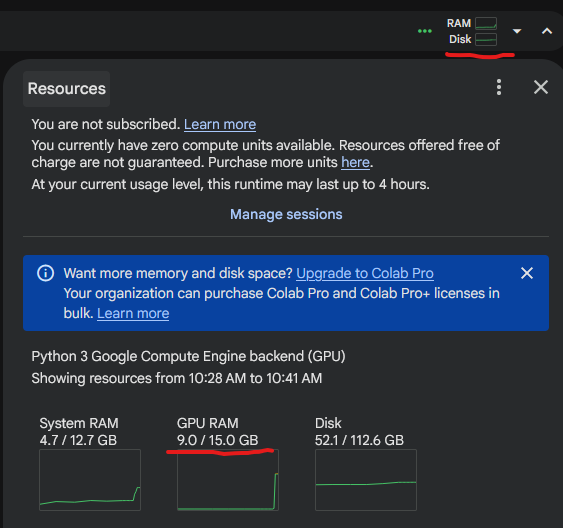

In [ ]:
# This will take at least 5 minutes to run
# Take the time to search/google/use AI to understand what each of the variables going into this function do
geoai.train_segmentation_model(
    images_dir=f"{tiles_dir}/images",
    labels_dir=f"{tiles_dir}/masks",
    output_dir=f"{tiles_dir}/unet_models",
    architecture="unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=6,
    num_classes=2,
    batch_size=8,
    num_epochs=3,
    learning_rate=0.001,
    val_split=0.2,
    verbose=True,
)

print('Training complete!')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Training complete!


**Q2**: Explain why using U-Net and ResNet34 together is a good choice when working with multi-spectral imagery. Use at least two references in your response.

*   U-Net, combined with a ResNet34 encoder, is well-suited to multispectral image segmentation because the two architectures play complementary roles. ResNet34 serves as the encoder, progressively extracting increasingly abstract spatial and spectral features from the six-band Sentinel-2 input. Its residual connections make deeper networks easier to optimise by allowing information and gradients to propagate effectively through the network (He et al., 2016). U-Net then provides the encoder–decoder structure required for semantic segmentation: the encoder captures broad contextual information while the decoder reconstructs a pixel-level classification, with skip connections transferring high-resolution spatial information from the encoder to the decoder (Ronneberger et al., 2015). This is particularly useful for retaining the boundaries of features such as rivers and lakes.

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. 2016 IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 770–778. https://doi.org/10.1109/CVPR.2016.90

Ronneberger, O., Fischer, P., & Brox, T. (2015). U-Net: Convolutional networks for biomedical image segmentation. In N. Navab, J. Hornegger, W. M. Wells, & A. F. Frangi (Eds.), Medical image computing and computer-assisted intervention – MICCAI 2015 (Lecture Notes in Computer Science, Vol. 9351, pp. 234–241). Springer. https://doi.org/10.1007/978-3-319-24574-4_28

**Q3**: What is the learning_rate and what is the likely effect that reducing it will have on your model?

*   The learning rate used in the model is 0.001. The learning rate controls how much the model's internal parameters are adjusted at each training step. A higher learning rate allows the model to learn more quickly, but if it is too large, the model may overshoot an optimal solution or become unstable.
*   Reducing the learning rate would generally make the training process slower but more controlled. Smaller updates can help the model refine its predictions more precisely and may improve performance once it is already close to a good solution. However, if the learning rate is made too small, training may take significantly longer, and the model may make very little progress between epochs.




This model took me 4 to 6 minutes to run on the GPU. If it is taking you more than that, check that you are not still stuck using a CPU (it will take a LOT longer if on a CPU).

With one line of code, we can now take a look at the model performance:

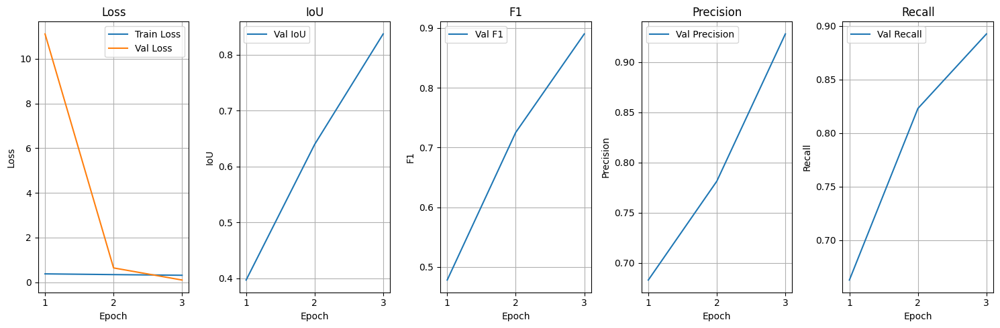

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.374551,11.115703,0.397035,0.478303,0.682793,0.662617
1,2,0.341662,0.640790,0.639610,0.725208,0.781343,0.823007
2,3,0.311666,0.098243,0.837193,0.889887,0.928122,0.892634


In [ ]:
# Performance statistics
geoai.plot_performance_metrics(
    history_path=f"{tiles_dir}/unet_models/training_history.pth",
    figsize=(15, 5),
    verbose=True,
)

**Q4**: Increase the number of training epochs to 10 (this will take some time, so maybe come back to this question later if need be). Present the resulting graphs of performance metrics in a figure and interpret the results for a technical audience (describe the training that has occured and make reccomendations for future training/use of the model). As always, figures should be of publication quality.

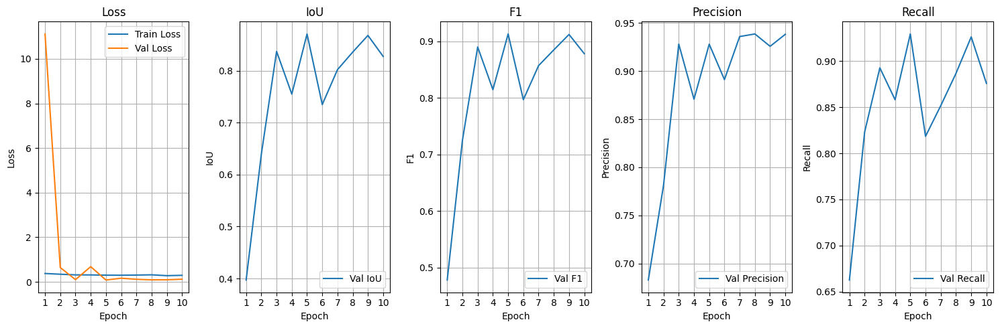

In [ ]:
# Q4 — retrain for 10 epochs and create the performance figure
# This overwrites/updates the model directory used by the following cells.

geoai.train_segmentation_model(
    images_dir=f"{tiles_dir}/images",
    labels_dir=f"{tiles_dir}/masks",
    output_dir=f"{tiles_dir}/unet_models",
    architecture="unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=6,
    num_classes=2,
    batch_size=8,
    num_epochs=10,
    learning_rate=0.001,
    val_split=0.2,
    verbose=True,
)

fig = geoai.plot_performance_metrics(
    history_path=f"{tiles_dir}/unet_models/training_history.pth",
    figsize=(15, 5),
    verbose=True,
)

# Save at publication-quality resolution if a Matplotlib Figure is returned.
if fig is not None and hasattr(fig, "savefig"):
    fig.savefig("Q4_water_training_metrics.png", dpi=300, bbox_inches="tight")


*   The model achieved consistently strong validation performance over the first nine epochs, with IoU, F1, precision and recall remaining relatively high and stable. This suggests that the model was successfully learning features that generalised to the validation imagery. However, at epoch 10, the validation loss increased sharply, and all validation metrics declined substantially, while the training loss remained low. This indicates a sudden loss of validation performance, likely due to training instability or reduced generalisation rather than normal, gradual overfitting. The model from approximately epoch 8-9 would therefore be preferable for subsequent prediction. Early stopping and a learning-rate scheduler could also be introduced to prevent further training once validation performance begins to decline.



In addition to these performance statistics, we can run [inference](https://www.cloudflare.com/learning/ai/inference-vs-training/) on the validation set to evaluate the model's performance. We will use the semantic_segmentation_batch function to process all the validation images at once.

In [ ]:
images_dir = f"{data_dir}/dset-s2/val_scene"
masks_dir = f"{data_dir}/dset-s2/val_truth"
predictions_dir = f"{data_dir}/dset-s2/predictions"
model_path = f"{tiles_dir}/unet_models/best_model.pth"

In [ ]:
geoai.semantic_segmentation_batch(
    input_dir=images_dir,
    output_dir=predictions_dir,
    model_path=model_path,
    architecture="unet",
    encoder_name="resnet34",
    num_channels=6,
    num_classes=2,
    window_size=512,
    overlap=128,
    batch_size=4,
    quiet=True,
)

And then visualize the results of this!

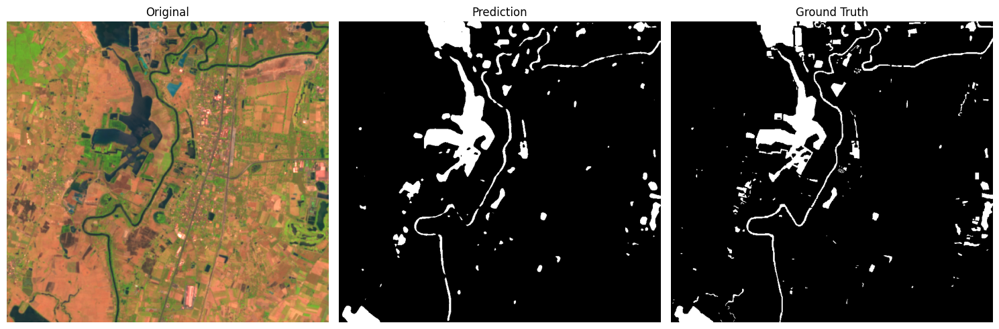

In [ ]:
# Visualize inference outcomes
image_id = "S2A_L2A_20190318_N0211_R061"  # Change to other image id, e.g., S2B_L2A_20190620_N0212_R047
test_image_path = f"{data_dir}/dset-s2/val_scene/{image_id}_6Bands_S2.tif"
ground_truth_path = f"{data_dir}/dset-s2/val_truth/{image_id}_S2_Truth.tif"
prediction_path = f"{data_dir}/dset-s2/predictions/{image_id}_6Bands_S2_mask.tif"
save_path = f"{data_dir}/dset-s2/{image_id}_6Bands_S2_comparison.png"

fig = geoai.plot_prediction_comparison(
    original_image=test_image_path,
    prediction_image=prediction_path,
    ground_truth_image=ground_truth_path,
    titles=["Original", "Prediction", "Ground Truth"],
    figsize=(15, 5),
    save_path=save_path,
    show_plot=True,
    indexes=[5, 4, 3],
    divider=5000,
)

In [ ]:
# ------------------------------------------------------------
# Q5 FILE PATHS — self-contained
# ------------------------------------------------------------

import os

image_id = "S2A_L2A_20190318_N0211_R061"

# Find the downloaded dset-s2 folder automatically
possible_roots = [
    ".",
    "/content",
    "/content/dset-s2"
]

dataset_root = None

for root in possible_roots:
    candidate = os.path.join(
        root,
        "dset-s2",
        "val_scene",
        f"{image_id}_6Bands_S2.tif"
    )

    if os.path.exists(candidate):
        dataset_root = os.path.join(root, "dset-s2")
        break

# Handle case where /content/dset-s2 itself is the root
if dataset_root is None:
    candidate = os.path.join(
        "/content/dset-s2",
        "val_scene",
        f"{image_id}_6Bands_S2.tif"
    )

    if os.path.exists(candidate):
        dataset_root = "/content/dset-s2"


if dataset_root is None:
    raise FileNotFoundError(
        "Could not find the dset-s2 dataset. "
        "Please rerun the workbook's 'Access the data' cell first."
    )


test_image_path = os.path.join(
    dataset_root,
    "val_scene",
    f"{image_id}_6Bands_S2.tif"
)

ground_truth_path = os.path.join(
    dataset_root,
    "val_truth",
    f"{image_id}_S2_Truth.tif"
)

prediction_path = os.path.join(
    dataset_root,
    "predictions",
    f"{image_id}_6Bands_S2_mask.tif"
)


print("Q5 files found:")
print("Image:       ", test_image_path)
print("Prediction:  ", prediction_path)
print("Ground truth:", ground_truth_path)

Q5 files found:
Image:        /content/dset-s2/dset-s2/val_scene/S2A_L2A_20190318_N0211_R061_6Bands_S2.tif
Prediction:   /content/dset-s2/dset-s2/predictions/S2A_L2A_20190318_N0211_R061_6Bands_S2_mask.tif
Ground truth: /content/dset-s2/dset-s2/val_truth/S2A_L2A_20190318_N0211_R061_S2_Truth.tif


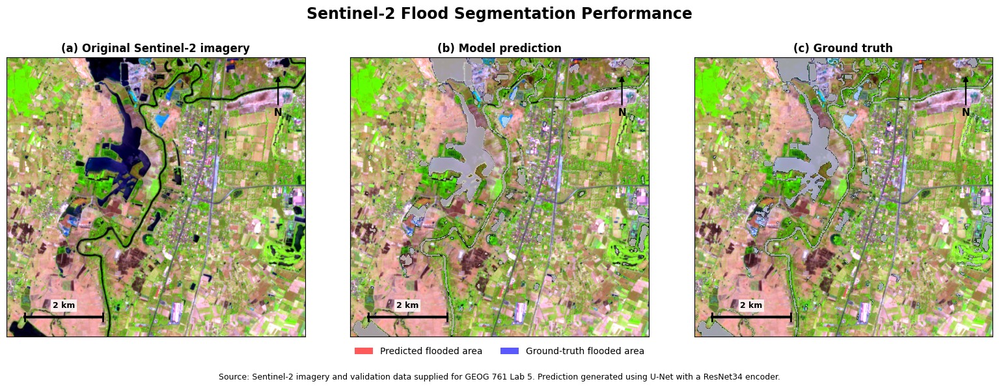

Saved: Q5_flood_segmentation_comparison.png


In [ ]:
# ============================================================
# Q5 — Publication-quality Sentinel-2 comparison
# Original | Prediction | Ground Truth
# ============================================================

import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pyproj import Transformer


# ------------------------------------------------------------
# READ SENTINEL-2 IMAGE
# Workbook uses bands [5, 4, 3] for display
# ------------------------------------------------------------

with rasterio.open(test_image_path) as src:
    rgb = src.read([5, 4, 3]).astype(np.float32)
    bounds = src.bounds
    crs = src.crs

rgb = np.moveaxis(rgb, 0, -1)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]


# Display stretch
for b in range(3):
    band = rgb[:, :, b]
    valid = band[np.isfinite(band)]

    if len(valid) > 0:
        low, high = np.percentile(valid, (2, 98))

        if high > low:
            rgb[:, :, b] = np.clip(
                (band - low) / (high - low),
                0, 1
            )


# ------------------------------------------------------------
# READ PREDICTION + GROUND TRUTH
# ------------------------------------------------------------

with rasterio.open(prediction_path) as src:
    prediction = src.read(1)

with rasterio.open(ground_truth_path) as src:
    truth = src.read(1)

prediction = prediction > 0
truth = truth > 0


# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def add_north_arrow(ax):
    ax.annotate(
        "N",
        xy=(0.91, 0.94),
        xytext=(0.91, 0.80),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.6,
            color="black"
        ),
        zorder=30
    )


def add_scale_bar(ax, length_m=5000):

    # Q5 raster is projected; map coordinates are in metres.
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()

    xr = x_max - x_min
    yr = y_max - y_min

    x0 = x_min + 0.06 * xr
    y0 = y_min + 0.07 * yr
    x1 = x0 + length_m

    ax.plot(
        [x0, x1], [y0, y0],
        color="black",
        linewidth=3,
        zorder=30
    )

    tick = 0.015 * yr

    ax.plot(
        [x0, x0],
        [y0 - tick, y0 + tick],
        color="black",
        linewidth=2,
        zorder=30
    )

    ax.plot(
        [x1, x1],
        [y0 - tick, y0 + tick],
        color="black",
        linewidth=2,
        zorder=30
    )

    ax.text(
        (x0 + x1) / 2,
        y0 + 0.025 * yr,
        f"{length_m / 1000:g} km",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8,
            pad=2
        ),
        zorder=31
    )


# ------------------------------------------------------------
# FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6)
)

titles = [
    "(a) Original Sentinel-2 imagery",
    "(b) Model prediction",
    "(c) Ground truth"
]

# Original
axes[0].imshow(
    rgb,
    extent=extent,
    origin="upper"
)

# Prediction
axes[1].imshow(
    rgb,
    extent=extent,
    origin="upper"
)

axes[1].imshow(
    np.ma.masked_where(~prediction, prediction),
    extent=extent,
    origin="upper",
    cmap="Reds",
    alpha=0.65,
    interpolation="none"
)

# Ground truth
axes[2].imshow(
    rgb,
    extent=extent,
    origin="upper"
)

axes[2].imshow(
    np.ma.masked_where(~truth, truth),
    extent=extent,
    origin="upper",
    cmap="Blues",
    alpha=0.65,
    interpolation="none"
)


for ax, title in zip(axes, titles):

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    add_north_arrow(ax)
    add_scale_bar(ax, length_m=2000)

    ax.set_xticks([])
    ax.set_yticks([])


fig.suptitle(
    "Sentinel-2 Flood Segmentation Performance",
    fontsize=17,
    fontweight="bold",
    y=0.97
)


# Legend
legend_elements = [
    Patch(
        facecolor="red",
        alpha=0.65,
        label="Predicted flooded area"
    ),
    Patch(
        facecolor="blue",
        alpha=0.65,
        label="Ground-truth flooded area"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(0.5, 0.055)
)


# Attribution
fig.text(
    0.5,
    0.015,
    "Source: Sentinel-2 imagery and validation data supplied for GEOG 761 Lab 5. "
    "Prediction generated using U-Net with a ResNet34 encoder.",
    ha="center",
    fontsize=9
)


plt.tight_layout(
    rect=[0, 0.10, 1, 0.93]
)

plt.savefig(
    "Q5_flood_segmentation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Q5_flood_segmentation_comparison.png")

**Q5**: Discuss the performance of the prediction in our example given above. Do so in reference to the ability of the prediction to resolve key features as compared to the ground truth (e.g. the river vs. the flood ponds). Explain why perfomance is varying in terms of both satellite data physical principles and the limitations of model and its training.

*   The model captures the main water bodies and much of the larger river network reasonably well, with the prediction showing strong agreement with the ground-truth mask in the central and upper portions of the image. However, the prediction is less accurate for narrow channels, small ponds and irregular shoreline features, where some water pixels are missed, or the predicted boundaries differ from the ground truth. There are also a small number of false-positive water detections in areas that are labelled as non-water in the reference mask.
*   This is likely due to the limited spatial resolution of the Sentinel-2 imagery and the greater spectral mixing that occurs around narrow waterways and shoreline pixels. Smaller or shallow water features may also have spectral characteristics that are less distinct from surrounding vegetation or soil. Overall, the model performs well for large, continuous water features, but its accuracy decreases for smaller and more spatially complex features.

Hopefully you can now see the difference that GeoAI makes to your workflow as compared to what we have gone through in the other labs.

Their library is doing a lot of the plumbing and model management for you behind the scenes, allowing you to write faster and solve different problems rather than getting stuck in the weeds. We have only imported one library to accomplish something that before we were using 5 or 6 to do. This does come with drawbacks, choices have been made for you- but particuarly for quick prototyping this is a strong advantage.

Note that the GeoAI tutorial also shows you [how to gather satellite data](https://opengeoai.org/workshops/TNView_2025/#download-sentinel-2-imagery) from a [STAC catalgoue](https://stacspec.org/en). This is the alternative (to the GEE approach used to date) way to build satellite data stacks for use in your project. Might well be useful for you in your projects...

# Task 2: Detecting solar panels from aerial imagery
In Task 1 we used semantic segmentation to classify pixels in satellite imagery. In this task we use a similar deep-learning workflow to identify solar panels in high-resolution aerial imagery, but then move from pixels to individual mapped objects.

The important distinction is that the U-Net produces a pixel-level segmentation. We will then convert that segmentation into polygons and use the geometry of those polygons to remove some of the small or implausible detections. This gives us a simple object-level workflow without introducing a separate object-detection model.

Before starting this task, clear the cache and make sure your RAM is empty from Task 1, or you may crash the Colab instance.

We will work with a labelled training image and vector dataset from Davis, California, and a separate aerial image for testing. The data are provided through [Hugging Face](https://huggingface.co/).

First, we will clear the data and model from Task 1 from our memory. You always want to make sure that a fresh model run has a clean memory to use, as otherwise these free instances will very quickly beocome jammed up and crash:

In [ ]:
# Clear memory before starting Task 2
import gc

# Python garbage collection
gc.collect()

# Clear PyTorch GPU memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

# Report current GPU memory
if torch.cuda.is_available():
    allocated = torch.cuda.memory_allocated() / 1024**3
    reserved = torch.cuda.memory_reserved() / 1024**3

    print("Memory cleared.")
    print(f"GPU memory allocated: {allocated:.2f} GB")
    print(f"GPU memory reserved:  {reserved:.2f} GB")
else:
    print("Memory cleared. No CUDA GPU detected.")

Memory cleared.
GPU memory allocated: 0.00 GB
GPU memory reserved:  0.00 GB


Next, we specify our data sources and then download them:

In [ ]:
# Set the URLS that you are getting the data from
train_raster_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_davis_ca.tif"
train_vector_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_davis_ca.geojson"
test_raster_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_test_davis_ca.tif"

In [ ]:
# Use GeoAI to download them
train_raster_path = geoai.download_file(train_raster_url)
train_vector_path = geoai.download_file(train_vector_url)
test_raster_path = geoai.download_file(test_raster_url)

Let's take a look at it using our own interactive view tool.

In [ ]:
show_interactive(raster=train_raster_path, vector=train_vector_path, title="Training scene")

NameError: name 'train_raster_path' is not defined

Q6: Examine the training image and labelled polygons. What visual characteristics distinguish the solar panels from the surrounding roofs, roads and vegetation? Identify at least two characteristics that a convolutional neural network could potentially learn from the imagery.

*   The labelled solar panels are visually distinctive because they are generally dark blue or black, rectangular, and arranged in regular groups on building roofs. Many of the arrays also contain repeated parallel lines or grid-like patterns that separate them from surrounding roof materials, vegetation, and roads. Their position on rooftops also provides useful contextual information.
*   A convolutional neural network can therefore learn a combination of colour and intensity features, texture, straight edges, rectangular shapes and repeated spatial patterns. It can also learn contextual relationships, such as the fact that solar panels are typically associated with roof surfaces rather than roads or vegetation. Combining these visual and spatial features helps the model distinguish genuine solar panels from other dark objects, such as roof shadows or dark roofing materials.



We now convert the labelled image into image/label tiles for training.

A 512 × 512 tile is large enough to contain complete solar-panel objects while still being manageable on a Colab GPU. The stride controls how much neighbouring tiles overlap.

In [ ]:
out_folder = "solar"
tiles = geoai.export_geotiff_tiles(
    in_raster=train_raster_path,
    out_folder=out_folder,
    in_class_data=train_vector_path,
    tile_size=512,
    stride=256,
    buffer_radius=0,
)

Generating tiles:   0%|          | 0/312 [00:00<?, ?it/s]

Train a U-Net segmentation model. As in Task 1, the model predicts a class for each pixel. Here the two classes are background and solar panel. This took me 3-5 minutes to train on the GPU. On the CPU it took over 30 minutes:

In [ ]:
geoai.train_segmentation_model(
    images_dir=f"{out_folder}/images",
    labels_dir=f"{out_folder}/labels",
    output_dir=f"{out_folder}/models",
    architecture="unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=3,
    num_classes=2,
    batch_size=8,
    num_epochs=10,
    learning_rate=1e-3,
    val_split=0.2,
)

Evaluate the model:

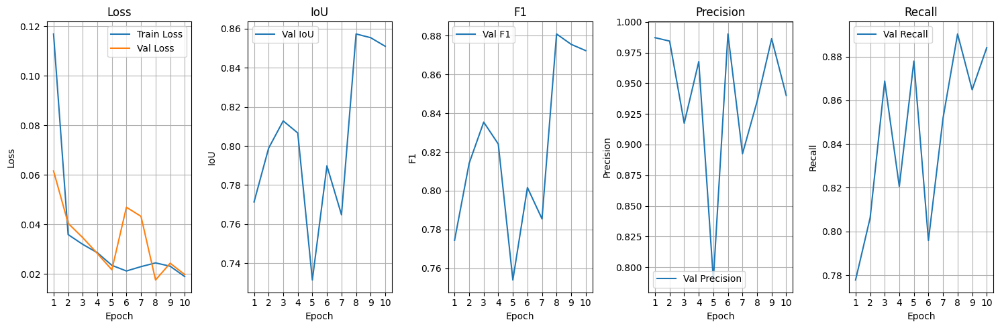

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.116936,0.061583,0.771366,0.774482,0.987177,0.777778
1,2,0.035870,0.040414,0.798876,0.814141,0.984386,0.806265
2,3,0.031917,0.034643,0.812815,0.835408,0.917417,0.868784
3,4,0.028560,0.028251,0.806637,0.824105,0.967680,0.820600
4,5,0.023441,0.021635,0.731401,0.753971,0.789540,0.877920
5,6,0.021153,0.046908,0.789834,0.801662,0.990221,0.795917
6,7,0.022909,0.043234,0.764787,0.785528,0.892552,0.851724
7,8,0.024422,0.017497,0.857315,0.880866,0.935167,0.890368
8,9,0.023081,0.024290,0.855401,0.875508,0.986340,0.864838
9,10,0.018896,0.019697,0.851000,0.872269,0.940119,0.884088


In [ ]:
geoai.plot_performance_metrics(
    history_path=f"{out_folder}/models/training_history.pth",
    figsize=(15, 5),
    verbose=True,
)

Q7: Examine the training and validation curves. Is there evidence that the model is still learning, or that it is beginning to overfit? What would you change about the training process if you wanted to improve the model further?

*   The model learns rapidly during the first few epochs, with training loss decreasing substantially and validation performance improving. However, after approximately epoch 5, the validation metrics fluctuate considerably. The highest validation IoU and F1 score occur around epoch 5, while performance drops sharply at epoch 7, recovers during epochs 8-9, and decreases again at epoch 10. Despite these fluctuations, the training and validation losses remain relatively low overall, with no consistent divergence between them, so the results do not provide strong evidence of conventional overfitting. Instead, the model appears to have largely converged, with some instability in its validation performance. Further training alone may therefore provide limited benefit. Using the best-performing checkpoint, approximately epoch 5, together with early stopping or a learning-rate scheduler, would provide a more robust approach.



Now apply the trained model to the unseen test image. In addition to the usual class mask, we will save the model's probability map. For a two-class problem, the second band contains the probability that each pixel belongs to the solar-panel class.

This is useful because the default mask hides how confident the model was. A pixel just above the classification boundary is different from a pixel for which the model is highly confident.

In [ ]:
masks_path = "solar_panels_prediction.tif"
probability_path = "solar_panels_probability.tif"
model_path = f"{out_folder}/models/best_model.pth"

geoai.semantic_segmentation(
    input_path=test_raster_path,
    output_path=masks_path,
    model_path=model_path,
    architecture="unet",
    encoder_name="resnet34",
    num_channels=3,
    num_classes=2,
    window_size=512,
    overlap=256,
    batch_size=8,
    probability_path=probability_path,
)

  0%|          | 0/209 [00:00<?, ?it/s]

Let's look at both the predicted mask.


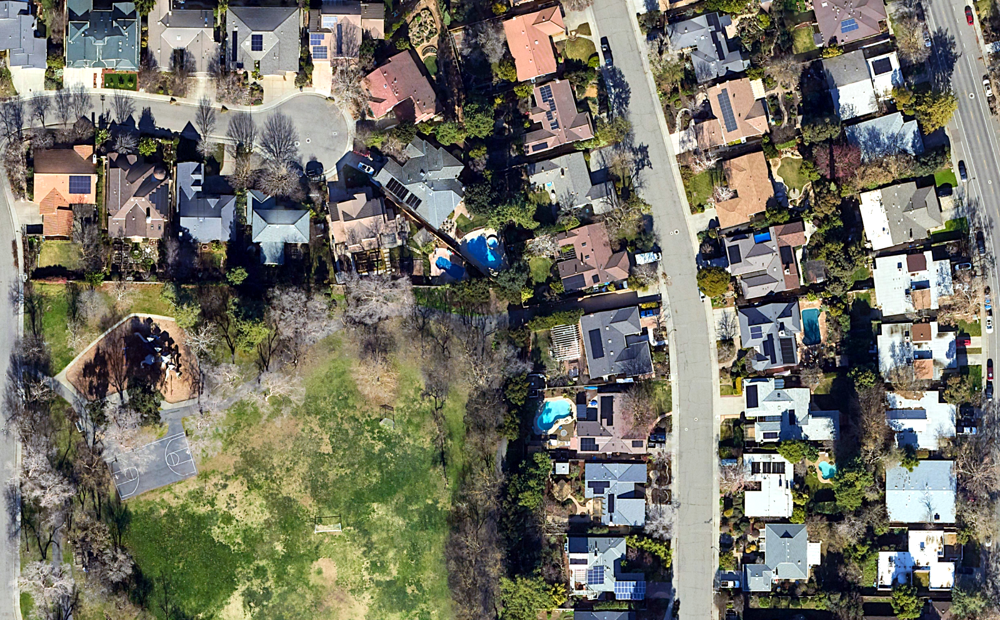
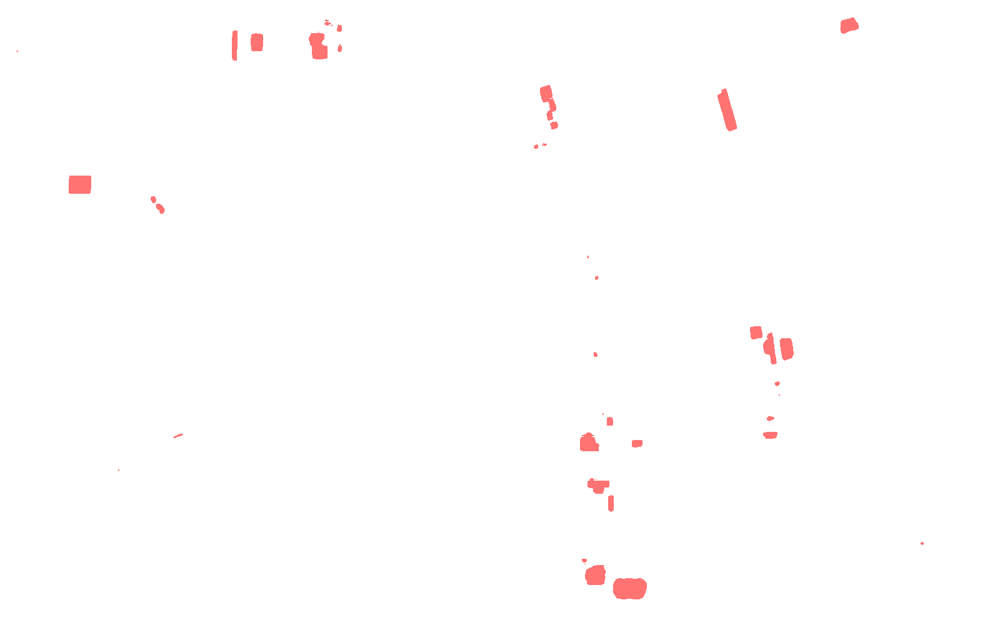
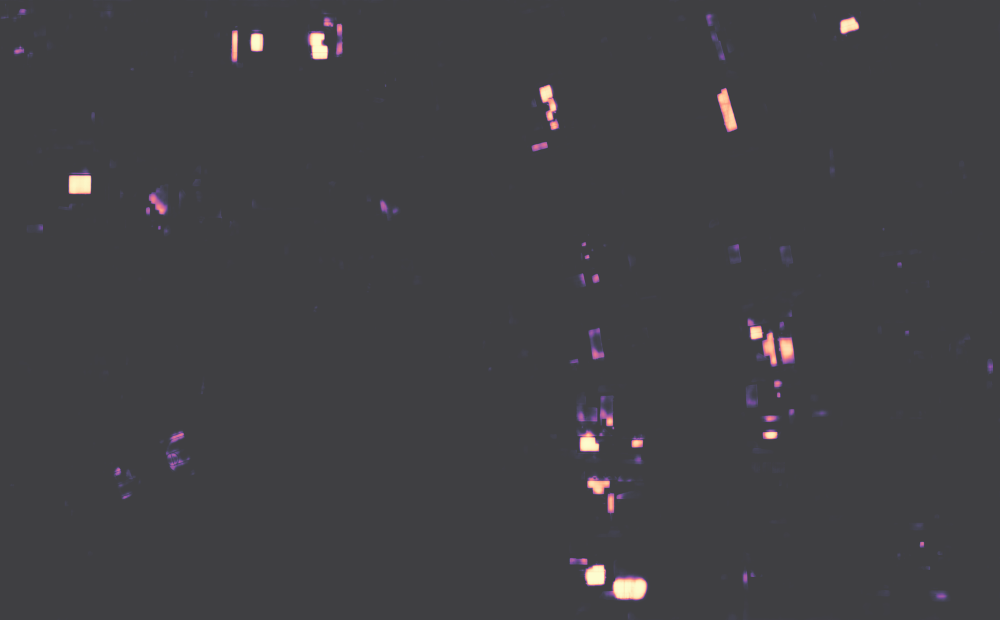

In [ ]:
show_interactive(raster=test_raster_path, mask=masks_path, probability=probability_path, title="Predictions")

Q8: Compare the binary mask with the probability map. Where does the model appear confident? Where does it appear uncertain? Why might a probability map be more useful than a binary mask when deciding how to improve a detection workflow?

*   The model shows the greatest confidence around clearly defined solar panel arrays on building rooftops, which appear as the brightest regions in the probability map. Larger and more visually distinct arrays generally produce stronger responses, while confidence decreases around panel edges, in smaller installations, and on more visually complex roof surfaces. Some lower-probability responses also occur over background features with similar colour, texture or geometry, indicating areas where the model is less certain.
*   The probability map provides more information than the final binary prediction because it shows the model’s confidence for each pixel. The binary mask only indicates whether a pixel has passed the selected classification threshold, whereas the probability map reveals which detections are strongly supported and which are more uncertain. This is useful for identifying potential false positives and for selecting an appropriate probability threshold during post-processing.



Improving the segmentation with a probability threshold:

The default binary result uses the model's class decision. We can instead specify a probability threshold for the solar-panel class. A lower threshold will normally retain more candidate pixels, while a higher threshold will normally produce fewer, more conservative detections.

Run the model again using a threshold of 0.7. Then compare this result with the original prediction.

  0%|          | 0/209 [00:00<?, ?it/s]


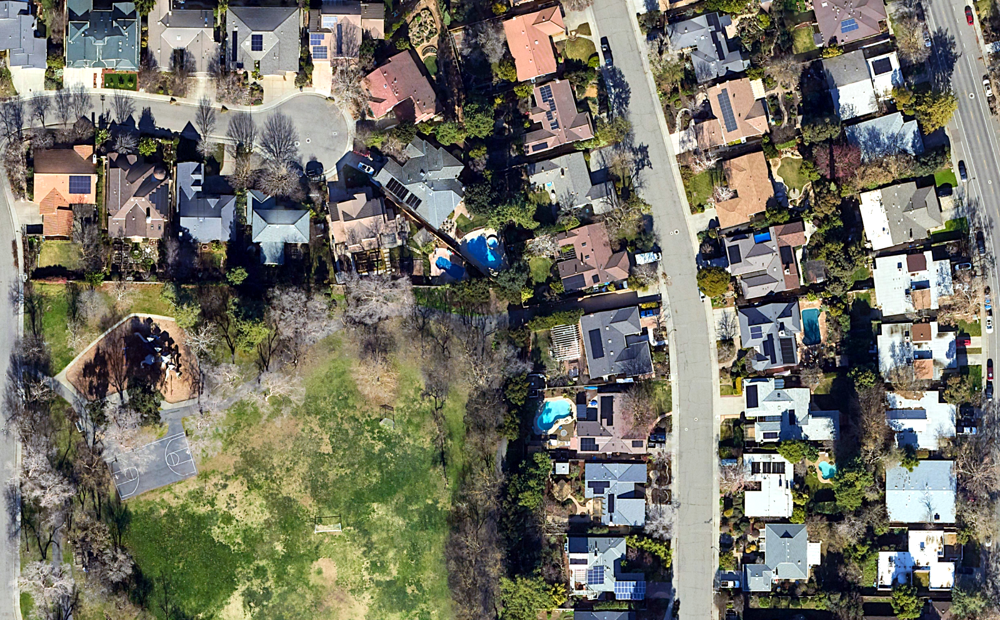
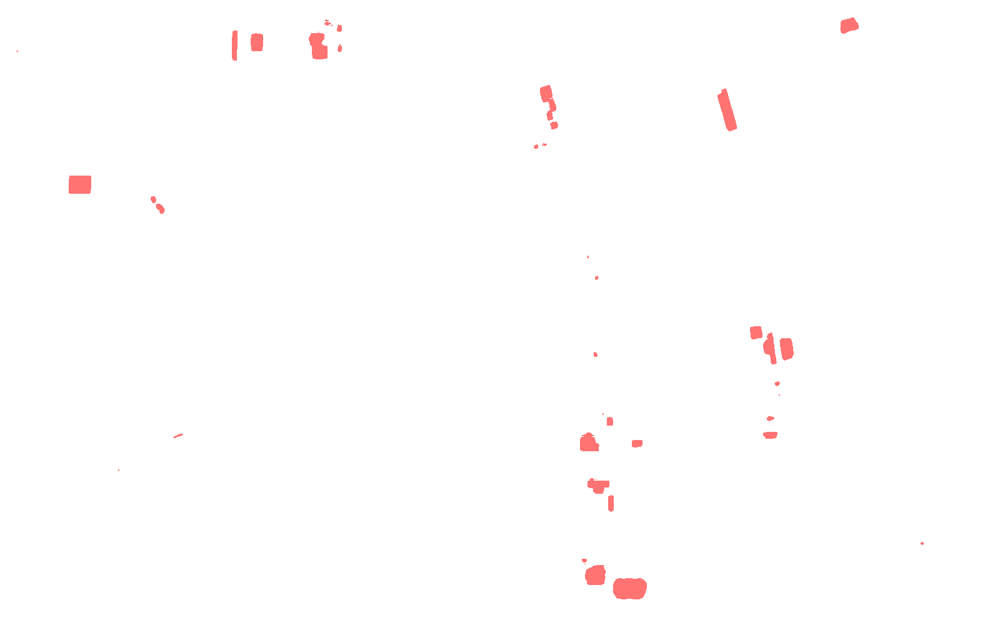
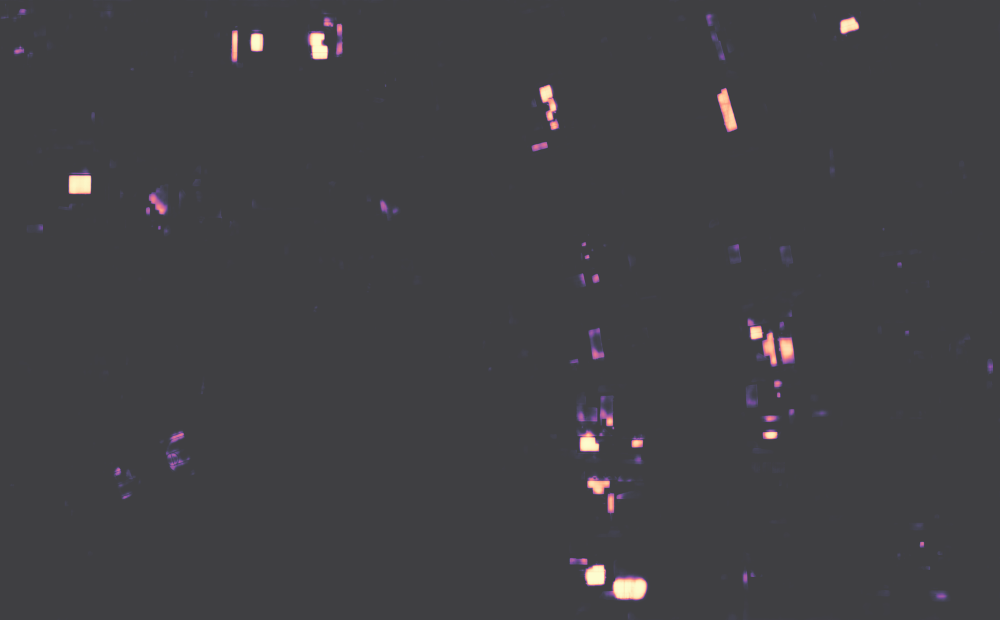

In [ ]:
threshold = 0.7
threshold_mask_path = f"solar_panels_prediction_{threshold:.1f}.tif"

geoai.semantic_segmentation(
    input_path=test_raster_path,
    output_path=threshold_mask_path,
    model_path=model_path,
    architecture="unet",
    encoder_name="resnet34",
    num_channels=3,
    num_classes=2,
    window_size=512,
    overlap=256,
    batch_size=8,
    probability_threshold=threshold,
)

show_interactive(raster=test_raster_path, mask=masks_path, probability=probability_path, title="Predictions")

Q9: Experiment with at least two different probability thresholds between 0.3 and 0.9. Compare the resulting masks visually. Which threshold gives you the most useful balance between retaining solar-panel pixels and rejecting false positives? Explain your choice using evidence from the imagery.

In [ ]:
# Q9 — compare several probability thresholds.
# IMPORTANT: the original lab cell displayed `masks_path` even after making the
# 0.7 threshold mask. The code below displays the correct threshold-specific mask.

thresholds = [0.4, 0.7, 0.9]
threshold_paths = {}

for t in thresholds:
    out = f"solar_panels_prediction_{t:.1f}.tif"
    geoai.semantic_segmentation(
        input_path=test_raster_path,
        output_path=out,
        model_path=model_path,
        architecture="unet",
        encoder_name="resnet34",
        num_channels=3,
        num_classes=2,
        window_size=512,
        overlap=256,
        batch_size=8,
        probability_threshold=t,
    )
    threshold_paths[t] = out
    print(f"Threshold {t:.1f}: {out}")

  0%|          | 0/209 [00:00<?, ?it/s]

Threshold 0.4: solar_panels_prediction_0.4.tif


  0%|          | 0/209 [00:00<?, ?it/s]

Threshold 0.7: solar_panels_prediction_0.7.tif


  0%|          | 0/209 [00:00<?, ?it/s]

Threshold 0.9: solar_panels_prediction_0.9.tif


In [ ]:
!pip install matplotlib-scalebar -q

Raster centre latitude: 38.5516°
Web Mercator ground-scale factor: 0.7820
Approximate true ground width: 287.3 m


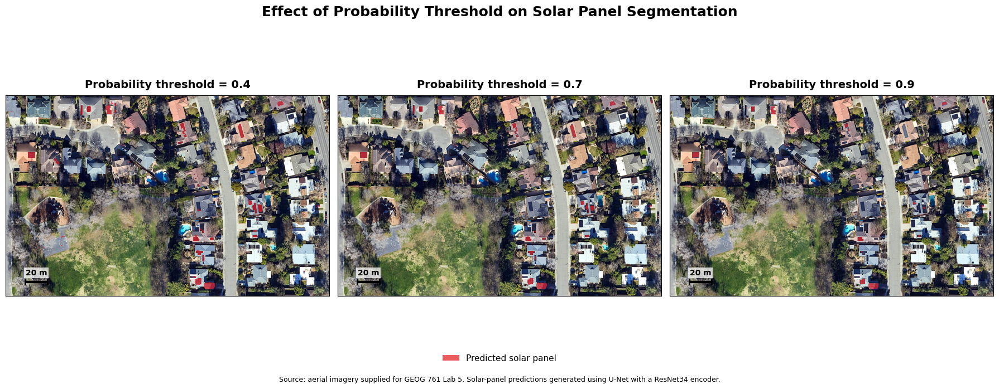

Saved:
  Q9_threshold_comparison.png
  Q9_threshold_comparison.pdf


In [ ]:
# Q9 — Publication-quality threshold comparison
# Corrects scale for EPSG:3857 (Web Mercator)

import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pyproj import Transformer


# ---------------------------------------------------------
# Read aerial imagery
# ---------------------------------------------------------
with rasterio.open(test_raster_path) as src:
    rgb = src.read([1, 2, 3]).astype(float)
    bounds = src.bounds
    crs = src.crs

rgb = np.moveaxis(rgb, 0, -1)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]


# ---------------------------------------------------------
# Stretch RGB imagery for display
# ---------------------------------------------------------
for b in range(3):
    band = rgb[:, :, b]

    valid = band[np.isfinite(band)]

    if len(valid) > 0:
        low, high = np.percentile(valid, (2, 98))

        if high > low:
            rgb[:, :, b] = np.clip(
                (band - low) / (high - low),
                0, 1
            )


# ---------------------------------------------------------
# Calculate Web Mercator ground-distance correction
# ---------------------------------------------------------

# Centre of raster in EPSG:3857
centre_x = (bounds.left + bounds.right) / 2
centre_y = (bounds.bottom + bounds.top) / 2

# Convert centre to latitude/longitude
transformer = Transformer.from_crs(
    "EPSG:3857",
    "EPSG:4326",
    always_xy=True
)

longitude, latitude = transformer.transform(
    centre_x,
    centre_y
)

# Web Mercator scale correction
ground_scale = np.cos(np.radians(latitude))

print(f"Raster centre latitude: {latitude:.4f}°")
print(f"Web Mercator ground-scale factor: {ground_scale:.4f}")

# Ground width of the displayed raster
mercator_width = bounds.right - bounds.left
ground_width = mercator_width * ground_scale

print(f"Approximate true ground width: {ground_width:.1f} m")


# ---------------------------------------------------------
# Function for an accurate manual scale bar
# ---------------------------------------------------------
def add_scale_bar(ax, length_m=20):

    # Convert desired TRUE ground distance back to
    # EPSG:3857 coordinate distance
    map_length = length_m / ground_scale

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    x_range = xmax - xmin
    y_range = ymax - ymin

    # Position near bottom-left
    x_start = xmin + 0.06 * x_range
    y_start = ymin + 0.07 * y_range

    x_end = x_start + map_length

    # Main line
    ax.plot(
        [x_start, x_end],
        [y_start, y_start],
        color="black",
        linewidth=3,
        solid_capstyle="butt",
        zorder=20
    )

    # End ticks
    tick_height = 0.012 * y_range

    ax.plot(
        [x_start, x_start],
        [y_start - tick_height, y_start + tick_height],
        color="black",
        linewidth=2,
        zorder=20
    )

    ax.plot(
        [x_end, x_end],
        [y_start - tick_height, y_start + tick_height],
        color="black",
        linewidth=2,
        zorder=20
    )

    # Label
    ax.text(
        (x_start + x_end) / 2,
        y_start + 0.025 * y_range,
        f"{length_m} m",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="black",
        bbox=dict(
            facecolor="white",
            alpha=0.75,
            edgecolor="none",
            pad=2
        ),
        zorder=21
    )


# ---------------------------------------------------------
# Create figure
# ---------------------------------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 7)
)

# Explicit prediction colour
prediction_colour = "#e31a1c"


for ax, t in zip(axes, thresholds):

    # Read threshold mask
    with rasterio.open(threshold_paths[t]) as src:
        mask = src.read(1)

    # Base imagery
    ax.imshow(
        rgb,
        extent=extent,
        origin="upper"
    )

    # -----------------------------------------------------
    # Create explicit RED overlay
    # -----------------------------------------------------

    predicted = mask > 0

    overlay = np.zeros(
        (mask.shape[0], mask.shape[1], 4),
        dtype=float
    )

    # RGB corresponding to #e31a1c
    overlay[..., 0] = 227 / 255
    overlay[..., 1] = 26 / 255
    overlay[..., 2] = 28 / 255

    # Only predicted pixels are visible
    overlay[..., 3] = predicted.astype(float) * 0.70

    ax.imshow(
        overlay,
        extent=extent,
        origin="upper",
        interpolation="none"
    )


    # -----------------------------------------------------
    # Title
    # -----------------------------------------------------
    ax.set_title(
        f"Probability threshold = {t:.1f}",
        fontsize=14,
        fontweight="bold",
        pad=10
    )


    # -----------------------------------------------------
    # North arrow
    # -----------------------------------------------------
    ax.annotate(
        "N",
        xy=(0.92, 0.95),
        xytext=(0.92, 0.82),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.8,
            color="black"
        ),
        zorder=30
    )


    # -----------------------------------------------------
    # Correct scale bar
    # -----------------------------------------------------
    add_scale_bar(
        ax,
        length_m=20
    )


    # Clean axes
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)


# ---------------------------------------------------------
# Legend — EXACT SAME RED as prediction
# ---------------------------------------------------------
legend_elements = [
    Patch(
        facecolor=prediction_colour,
        alpha=0.70,
        label="Predicted solar panel"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.035)
)


# ---------------------------------------------------------
# Main title
# ---------------------------------------------------------
fig.suptitle(
    "Effect of Probability Threshold on Solar Panel Segmentation",
    fontsize=18,
    fontweight="bold",
    y=0.97
)


# ---------------------------------------------------------
# Data attribution
# ---------------------------------------------------------
fig.text(
    0.5,
    0.005,
    "Source: aerial imagery supplied for GEOG 761 Lab 5. "
    "Solar-panel predictions generated using U-Net with a ResNet34 encoder.",
    ha="center",
    fontsize=9
)


# Give room for title + legend + attribution
plt.tight_layout(
    rect=[0, 0.08, 1, 0.94]
)


# ---------------------------------------------------------
# Export
# ---------------------------------------------------------
plt.savefig(
    "Q9_threshold_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Q9_threshold_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print("  Q9_threshold_comparison.png")
print("  Q9_threshold_comparison.pdf")

From pixels to objects:

The segmentation is still a raster. For many mapping applications we want individual features that can be counted, measured and filtered. We therefore convert the selected mask to polygons and regularise the polygon shapes.

In [ ]:
output_path = "solar_panels_prediction.geojson"
gdf = geoai.orthogonalize(threshold_mask_path, output_path, epsilon=2)

print(f"Number of polygons before filtering: {len(gdf)}")

Converting features:   0%|          | 0/21 [00:00<?, ?shape/s]

Number of polygons before filtering: 20


We can now calculate geometric properties for every predicted object. This gives us information such as area, perimeter and shape characteristics that were not available in the raster mask.

In [ ]:
gdf_props = geoai.add_geometric_properties(
    gdf,
    area_unit="m2",
    length_unit="m",
)

print(gdf_props[["area_m2", "length_m", "elongation", "solidity"]].describe())

         area_m2   length_m  elongation   solidity
count  20.000000  20.000000   20.000000  20.000000
mean   25.702464  24.559482    2.000381   0.914639
std    20.040297  12.060756    1.182078   0.071995
min     0.729994   4.329644    1.020870   0.687696
25%     8.847691  13.847455    1.193125   0.891264
50%    23.666283  24.186152    1.562370   0.941740
75%    35.390762  31.464565    2.059527   0.960259
max    78.259780  47.476602    5.458135   0.981655


Inspect the distribution of object sizes and shapes, then apply a simple geometric filter. Solar panels are relatively compact, regular objects, whereas tiny isolated detections are often artefacts of the segmentation.

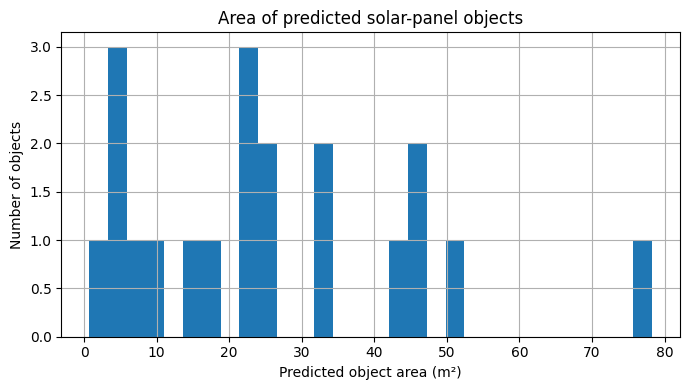

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
gdf_props["area_m2"].hist(bins=30, ax=ax)
ax.set_xlabel("Predicted object area (m²)")
ax.set_ylabel("Number of objects")
ax.set_title("Area of predicted solar-panel objects")
plt.tight_layout()
plt.show()

Q10: Based on the area distribution and the map, choose a minimum object area that removes obvious small artefacts without removing genuine solar panels. State the threshold you chose and explain the trade-off.

Detected objects: 20
Raster centre latitude: 38.5516°
Minimum-area threshold: 5.0 m²
Objects before filtering: 20
Objects retained: 15
Objects removed: 5

Object areas (m²):
[ 0.45  2.03  2.41  3.03  4.28  5.79  9.07 10.03 13.6  14.47 14.48 15.68
 15.85 19.47 20.1  26.29 28.82 28.88 31.81 47.86]


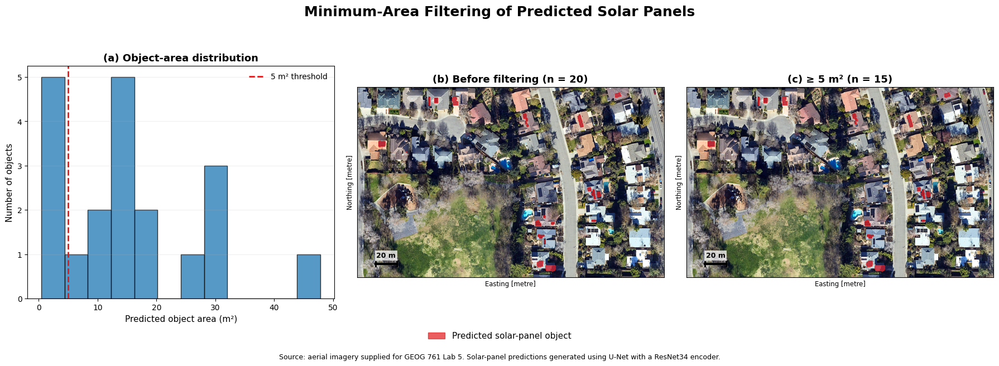


Saved:
  Q10_area_filtering.png
  Q10_area_filtering.pdf


In [ ]:
# Q10 — Object-area distribution and minimum-area filtering
#
# Produces:
#   (a) object-area distribution
#   (b) all detected objects
#   (c) objects retained after a 5 m² minimum-area filter

import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from rasterio.features import shapes
from shapely.geometry import shape
from pyproj import Transformer
import geopandas as gpd


# ---------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------

mask_path = threshold_paths[0.7]
min_area = 5.0              # minimum TRUE ground area, m²
prediction_colour = "#e31a1c"


# ---------------------------------------------------------
# Read selected 0.7 mask
# ---------------------------------------------------------

with rasterio.open(mask_path) as src:
    mask = src.read(1)
    mask_transform = src.transform
    mask_crs = src.crs


# ---------------------------------------------------------
# Convert predicted regions into polygons
# ---------------------------------------------------------

binary_mask = (mask > 0).astype(np.uint8)

features = []

for geom, value in shapes(
    binary_mask,
    mask=binary_mask.astype(bool),
    transform=mask_transform
):
    if value == 1:
        features.append(shape(geom))

objects = gpd.GeoDataFrame(
    geometry=features,
    crs=mask_crs
)

print(f"Detected objects: {len(objects)}")


# ---------------------------------------------------------
# Correct EPSG:3857 areas to approximate true ground area
#
# Web Mercator area is enlarged by approximately:
#     1 / cos(latitude)^2
#
# Therefore:
#     ground area = Mercator area × cos(latitude)^2
# ---------------------------------------------------------

with rasterio.open(test_raster_path) as src:
    bounds = src.bounds

centre_x = (bounds.left + bounds.right) / 2
centre_y = (bounds.bottom + bounds.top) / 2

transformer = Transformer.from_crs(
    "EPSG:3857",
    "EPSG:4326",
    always_xy=True
)

longitude, latitude = transformer.transform(
    centre_x,
    centre_y
)

ground_scale = np.cos(np.radians(latitude))

objects["area_mercator"] = objects.geometry.area
objects["area_m2"] = objects["area_mercator"] * ground_scale**2


# ---------------------------------------------------------
# Apply 5 m² area filter
# ---------------------------------------------------------

objects["retained"] = objects["area_m2"] >= min_area

retained = objects[objects["retained"]].copy()
removed = objects[~objects["retained"]].copy()


# ---------------------------------------------------------
# Print useful statistics
# ---------------------------------------------------------

print(f"Raster centre latitude: {latitude:.4f}°")
print(f"Minimum-area threshold: {min_area:.1f} m²")

print(
    f"Objects before filtering: {len(objects)}"
)

print(
    f"Objects retained: {len(retained)}"
)

print(
    f"Objects removed: {len(removed)}"
)

print("\nObject areas (m²):")

print(
    np.round(
        np.sort(objects["area_m2"].values),
        2
    )
)


# ---------------------------------------------------------
# Read RGB imagery
# ---------------------------------------------------------

with rasterio.open(test_raster_path) as src:

    rgb = src.read([1, 2, 3]).astype(float)

    bounds = src.bounds

rgb = np.moveaxis(rgb, 0, -1)

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]


# Percentile stretch
for b in range(3):

    band = rgb[:, :, b]

    valid = band[np.isfinite(band)]

    if len(valid) > 0:

        low, high = np.percentile(
            valid,
            (2, 98)
        )

        if high > low:

            rgb[:, :, b] = np.clip(
                (band - low) /
                (high - low),
                0,
                1
            )


# ---------------------------------------------------------
# Helper: north arrow
# ---------------------------------------------------------

def add_north_arrow(ax):

    ax.annotate(
        "N",
        xy=(0.92, 0.95),
        xytext=(0.92, 0.82),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.7,
            color="black"
        ),
        zorder=30
    )


# ---------------------------------------------------------
# Helper: corrected 20 m scale bar
# ---------------------------------------------------------

def add_scale_bar(ax, length_m=20):

    map_length = length_m / ground_scale

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    xr = xmax - xmin
    yr = ymax - ymin

    x0 = xmin + 0.06 * xr
    y0 = ymin + 0.07 * yr

    x1 = x0 + map_length

    # horizontal bar
    ax.plot(
        [x0, x1],
        [y0, y0],
        color="black",
        linewidth=3,
        zorder=30
    )

    # end ticks
    tick = 0.012 * yr

    ax.plot(
        [x0, x0],
        [y0 - tick, y0 + tick],
        color="black",
        linewidth=2,
        zorder=30
    )

    ax.plot(
        [x1, x1],
        [y0 - tick, y0 + tick],
        color="black",
        linewidth=2,
        zorder=30
    )

    # label
    ax.text(
        (x0 + x1) / 2,
        y0 + 0.025 * yr,
        f"{length_m} m",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.75,
            pad=2
        ),
        zorder=31
    )


# ---------------------------------------------------------
# CREATE FIGURE
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6.5)
)


# =========================================================
# (a) AREA DISTRIBUTION
# =========================================================

ax = axes[0]

areas = np.sort(objects["area_m2"].values)

ax.hist(
    areas,
    bins=12,
    edgecolor="black",
    alpha=0.75
)

# Threshold
ax.axvline(
    min_area,
    linestyle="--",
    linewidth=2,
    color=prediction_colour,
    label=f"{min_area:.0f} m² threshold"
)

ax.set_xlabel(
    "Predicted object area (m²)",
    fontsize=11
)

ax.set_ylabel(
    "Number of objects",
    fontsize=11
)

ax.set_title(
    "(a) Object-area distribution",
    fontsize=13,
    fontweight="bold"
)

ax.legend(
    frameon=False,
    fontsize=10
)

ax.grid(
    axis="y",
    alpha=0.2
)


# =========================================================
# (b) ALL DETECTED OBJECTS
# =========================================================

ax = axes[1]

ax.imshow(
    rgb,
    extent=extent,
    origin="upper"
)

objects.plot(
    ax=ax,
    facecolor=prediction_colour,
    edgecolor=prediction_colour,
    alpha=0.70
)

ax.set_title(
    f"(b) Before filtering (n = {len(objects)})",
    fontsize=13,
    fontweight="bold"
)

add_north_arrow(ax)
add_scale_bar(ax)

ax.set_xticks([])
ax.set_yticks([])


# =========================================================
# (c) FILTERED OBJECTS
# =========================================================

ax = axes[2]

ax.imshow(
    rgb,
    extent=extent,
    origin="upper"
)

retained.plot(
    ax=ax,
    facecolor=prediction_colour,
    edgecolor=prediction_colour,
    alpha=0.70
)

ax.set_title(
    f"(c) ≥ {min_area:.0f} m² (n = {len(retained)})",
    fontsize=13,
    fontweight="bold"
)

add_north_arrow(ax)
add_scale_bar(ax)

ax.set_xticks([])
ax.set_yticks([])


# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

legend_elements = [
    Patch(
        facecolor=prediction_colour,
        edgecolor=prediction_colour,
        alpha=0.70,
        label="Predicted solar-panel object"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.035)
)


# ---------------------------------------------------------
# Overall title
# ---------------------------------------------------------

fig.suptitle(
    "Minimum-Area Filtering of Predicted Solar Panels",
    fontsize=18,
    fontweight="bold",
    y=0.98
)


# ---------------------------------------------------------
# Attribution
# ---------------------------------------------------------

fig.text(
    0.5,
    0.005,
    "Source: aerial imagery supplied for GEOG 761 Lab 5. "
    "Solar-panel predictions generated using U-Net with a ResNet34 encoder.",
    ha="center",
    fontsize=9
)


plt.tight_layout(
    rect=[0, 0.08, 1, 0.93]
)


# ---------------------------------------------------------
# Export
# ---------------------------------------------------------

plt.savefig(
    "Q10_area_filtering.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Q10_area_filtering.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print("  Q10_area_filtering.png")
print("  Q10_area_filtering.pdf")

Note: I have left the vector display as the default settings and they are a little hard to see... you may want to go and expand the code cell at the top of the lab that does the 'show_interactive' and see if you can make it better...

In [ ]:
# Change this value after inspecting the area distribution and map.
min_area = 5

gdf_filtered = gdf_props[gdf_props["area_m2"] >= min_area].copy()

print(f"Objects before filtering: {len(gdf_props)}")
print(f"Objects after filtering:  {len(gdf_filtered)}")
print(f"Objects removed:          {len(gdf_props) - len(gdf_filtered)}")

Objects before filtering: 20
Objects after filtering:  16
Objects removed:          4


In [ ]:
show_interactive(raster=test_raster_path, vector=gdf_filtered, vector_column="area_m2", title="Filtered detections")

Q11: Inspect the filtered predictions against the imagery. Identify two examples where the model has worked well and two examples where it has failed or produced an ambiguous result. For each case, suggest a likely reason for the error.

Raster centre latitude: 38.5516°
Ground scale factor: 0.7820
Objects before filtering: 20
Objects retained ≥ 5.0 m²: 15


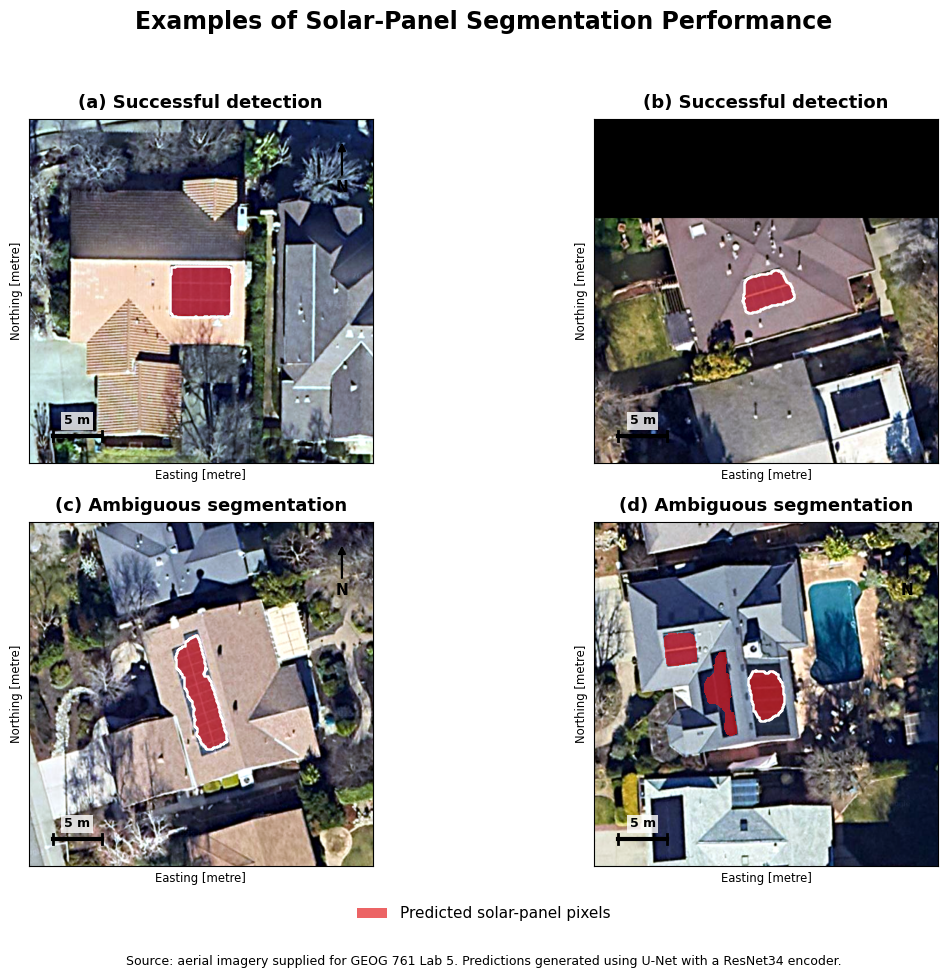


Saved: Q11_model_performance_examples.png


In [ ]:
# ============================================================
# Q11 — Examples of successful and ambiguous model predictions
# SELF-CONTAINED VERSION
# ============================================================

import rasterio
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

from rasterio.features import shapes
from rasterio.windows import from_bounds
from shapely.geometry import shape
from pyproj import Transformer
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. FILES
# ------------------------------------------------------------

image_path = "solar_panels_test_davis_ca.tif"
mask_path = "solar_panels_prediction_0.7.tif"

# Q10 minimum-area threshold
min_area = 5.0


# ------------------------------------------------------------
# 2. CALCULATE WEB MERCATOR SCALE CORRECTION
# ------------------------------------------------------------

with rasterio.open(image_path) as src:
    bounds = src.bounds

centre_x = (bounds.left + bounds.right) / 2
centre_y = (bounds.bottom + bounds.top) / 2

transformer = Transformer.from_crs(
    "EPSG:3857",
    "EPSG:4326",
    always_xy=True
)

longitude, latitude = transformer.transform(
    centre_x,
    centre_y
)

ground_scale = np.cos(np.radians(latitude))

print(f"Raster centre latitude: {latitude:.4f}°")
print(f"Ground scale factor: {ground_scale:.4f}")


# ------------------------------------------------------------
# 3. READ 0.7 MASK AND CREATE OBJECTS
# ------------------------------------------------------------

with rasterio.open(mask_path) as src:

    mask = src.read(1)
    mask_transform = src.transform
    mask_crs = src.crs


binary_mask = (mask > 0).astype(np.uint8)

geometries = []

for geom, value in shapes(
    binary_mask,
    mask=binary_mask.astype(bool),
    transform=mask_transform
):

    if value == 1:
        geometries.append(shape(geom))


objects = gpd.GeoDataFrame(
    geometry=geometries,
    crs=mask_crs
)


# ------------------------------------------------------------
# 4. CALCULATE TRUE APPROXIMATE GROUND AREA
# ------------------------------------------------------------

objects["area_mercator"] = objects.geometry.area

objects["area_m2"] = (
    objects["area_mercator"] *
    ground_scale**2
)


# ------------------------------------------------------------
# 5. APPLY Q10 FILTER
# ------------------------------------------------------------

retained = objects[
    objects["area_m2"] >= min_area
].copy()

retained = retained.reset_index(drop=True)

# Number objects 1–15
retained["ID"] = range(
    1,
    len(retained) + 1
)

print(f"Objects before filtering: {len(objects)}")
print(f"Objects retained ≥ {min_area:.1f} m²: {len(retained)}")


# ------------------------------------------------------------
# 6. SELECT Q11 EXAMPLES
#
# From the numbered overview:
#   7 & 1 = strong examples
#   6 & 9 = ambiguous examples
#
# 9's zoom should also show the neighbouring 8–10 region.
# ------------------------------------------------------------

examples = [
    (7, "(a) Successful detection"),
    (1, "(b) Successful detection"),
    (6, "(c) Ambiguous segmentation"),
    (9, "(d) Ambiguous segmentation")
]


# ------------------------------------------------------------
# 7. SETTINGS
# ------------------------------------------------------------

# Width of each zoom on the ground
zoom_ground_m = 35

prediction_colour = "#e31a1c"

# Transparent background + red prediction
red_cmap = ListedColormap([
    (0, 0, 0, 0),
    (227/255, 26/255, 28/255, 0.68)
])


# ------------------------------------------------------------
# 8. SCALE BAR FUNCTION
# ------------------------------------------------------------

def add_scale_bar(ax, length_m=5):

    # Convert real ground metres to EPSG:3857 map units
    map_length = length_m / ground_scale

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    xr = xmax - xmin
    yr = ymax - ymin

    x0 = xmin + 0.07 * xr
    y0 = ymin + 0.08 * yr

    x1 = x0 + map_length

    # Horizontal bar
    ax.plot(
        [x0, x1],
        [y0, y0],
        color="black",
        linewidth=3,
        zorder=30
    )

    # End ticks
    tick = 0.015 * yr

    ax.plot(
        [x0, x0],
        [y0 - tick, y0 + tick],
        color="black",
        linewidth=2,
        zorder=30
    )

    ax.plot(
        [x1, x1],
        [y0 - tick, y0 + tick],
        color="black",
        linewidth=2,
        zorder=30
    )

    # Label
    ax.text(
        (x0 + x1) / 2,
        y0 + 0.025 * yr,
        f"{length_m} m",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8,
            pad=2
        ),
        zorder=31
    )


# ------------------------------------------------------------
# 9. NORTH ARROW FUNCTION
# ------------------------------------------------------------

def add_north_arrow(ax):

    ax.annotate(
        "N",
        xy=(0.91, 0.94),
        xytext=(0.91, 0.80),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.6,
            color="black"
        ),
        zorder=40
    )


# ------------------------------------------------------------
# 10. CREATE FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

axes = axes.flatten()


# Open imagery and mask only once
with rasterio.open(image_path) as image_src, \
     rasterio.open(mask_path) as mask_src:

    for ax, (object_id, panel_title) in zip(
        axes,
        examples
    ):

        # ----------------------------------------------------
        # Selected object
        # ----------------------------------------------------

        row = retained.loc[
            retained["ID"] == object_id
        ].iloc[0]

        centroid = row.geometry.centroid


        # ----------------------------------------------------
        # Define 35 × 35 m ground zoom
        # ----------------------------------------------------

        zoom_map = zoom_ground_m / ground_scale
        half = zoom_map / 2

        xmin = centroid.x - half
        xmax = centroid.x + half
        ymin = centroid.y - half
        ymax = centroid.y + half


        # ----------------------------------------------------
        # Read ONLY the required RGB window
        # ----------------------------------------------------

        image_window = from_bounds(
            xmin,
            ymin,
            xmax,
            ymax,
            image_src.transform
        )

        rgb = image_src.read(
            [1, 2, 3],
            window=image_window,
            boundless=True,
            fill_value=0
        ).astype(np.float32)

        rgb = np.moveaxis(
            rgb,
            0,
            -1
        )


        # ----------------------------------------------------
        # Percentile stretch
        # ----------------------------------------------------

        for b in range(3):

            band = rgb[:, :, b]

            valid = band[
                np.isfinite(band) &
                (band > 0)
            ]

            if len(valid) > 0:

                low, high = np.percentile(
                    valid,
                    (2, 98)
                )

                if high > low:

                    rgb[:, :, b] = np.clip(
                        (band - low) /
                        (high - low),
                        0,
                        1
                    )


        # ----------------------------------------------------
        # Read ONLY corresponding prediction window
        # ----------------------------------------------------

        mask_window = from_bounds(
            xmin,
            ymin,
            xmax,
            ymax,
            mask_src.transform
        )

        mask_crop = mask_src.read(
            1,
            window=mask_window,
            boundless=True,
            fill_value=0
        )

        mask_crop = (
            mask_crop > 0
        ).astype(np.uint8)


        # ----------------------------------------------------
        # Plot original imagery
        # ----------------------------------------------------

        crop_extent = [
            xmin,
            xmax,
            ymin,
            ymax
        ]

        ax.imshow(
            rgb,
            extent=crop_extent,
            origin="upper"
        )


        # ----------------------------------------------------
        # Prediction overlay
        # ----------------------------------------------------

        prediction = np.ma.masked_where(
            mask_crop == 0,
            mask_crop
        )

        ax.imshow(
            prediction,
            extent=crop_extent,
            origin="upper",
            cmap=red_cmap,
            interpolation="nearest",
            vmin=0,
            vmax=1
        )


        # ----------------------------------------------------
        # Highlight selected object with white boundary
        # ----------------------------------------------------

        retained[
            retained["ID"] == object_id
        ].plot(
            ax=ax,
            facecolor="none",
            edgecolor="white",
            linewidth=1.8,
            zorder=20
        )


        # ----------------------------------------------------
        # Keep consistent scale
        # ----------------------------------------------------

        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)

        ax.set_aspect("equal")


        # ----------------------------------------------------
        # Panel title
        # ----------------------------------------------------

        ax.set_title(
            panel_title,
            fontsize=13,
            fontweight="bold",
            pad=8
        )


        # ----------------------------------------------------
        # Cartographic elements
        # ----------------------------------------------------

        add_north_arrow(ax)
        add_scale_bar(ax, length_m=5)

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_linewidth(0.8)


# ------------------------------------------------------------
# 11. OVERALL TITLE
# ------------------------------------------------------------

fig.suptitle(
    "Examples of Solar-Panel Segmentation Performance",
    fontsize=17,
    fontweight="bold",
    y=0.97
)


# ------------------------------------------------------------
# 12. LEGEND
# ------------------------------------------------------------

legend_elements = [
    Patch(
        facecolor=prediction_colour,
        alpha=0.68,
        label="Predicted solar-panel pixels"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    frameon=False,
    fontsize=11,
    bbox_to_anchor=(0.5, 0.045)
)


# ------------------------------------------------------------
# 13. ATTRIBUTION
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    "Source: aerial imagery supplied for GEOG 761 Lab 5. "
    "Predictions generated using U-Net with a ResNet34 encoder.",
    ha="center",
    fontsize=9
)


plt.tight_layout(
    rect=[0, 0.08, 1, 0.94]
)


# ------------------------------------------------------------
# 14. EXPORT
# ------------------------------------------------------------

plt.savefig(
    "Q11_model_performance_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved: Q11_model_performance_examples.png")

Q12: Produce a publication-quality figure from your final result and write a short technical paragraph explaining the complete workflow. Your paragraph should describe:

*   how the training data were created
*   how the U-Net was trained and evaluated;
*   how the probability threshold affected the prediction;
*   how raster predictions were converted into objects
*   how geometric filtering changed the final result

Your discussion should distinguish between what the model learned during training and what you achieved through post-processing. Include references to any external materials you used.

As a final reflection: this workflow is semantic segmentation followed by object extraction, rather than a dedicated object-detection model. Explain one advantage and one limitation of this approach for mapping solar panels.

Centre latitude: 38.5516°
Ground-scale factor: 0.7820
Objects before filtering: 20
Final objects retained: 15


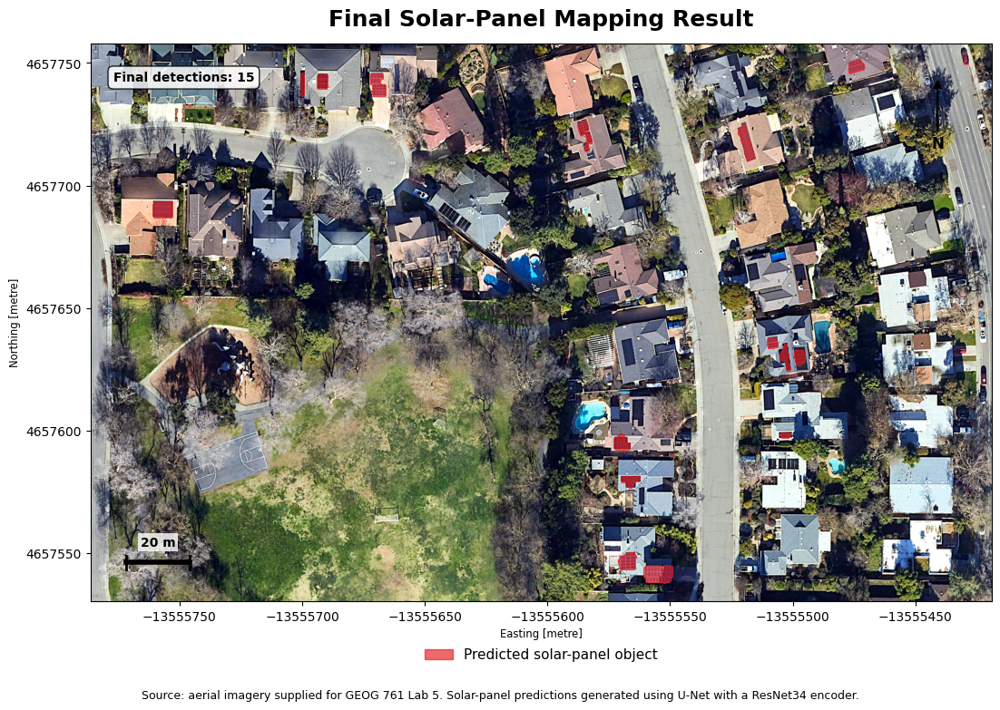

Saved: Q12_final_solar_panel_map.png


In [ ]:
# ============================================================
# Q12 — Publication-quality final solar-panel mapping result
# SELF-CONTAINED
# ============================================================

import rasterio
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

from rasterio.features import shapes
from shapely.geometry import shape
from pyproj import Transformer
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. FILES AND FINAL PARAMETERS
# ------------------------------------------------------------

image_path = "solar_panels_test_davis_ca.tif"
mask_path = "solar_panels_prediction_0.7.tif"

probability_threshold = 0.7
min_area = 5.0


# ------------------------------------------------------------
# 2. CALCULATE EPSG:3857 GROUND-SCALE CORRECTION
# ------------------------------------------------------------

with rasterio.open(image_path) as src:
    bounds = src.bounds

centre_x = (bounds.left + bounds.right) / 2
centre_y = (bounds.bottom + bounds.top) / 2

transformer = Transformer.from_crs(
    "EPSG:3857",
    "EPSG:4326",
    always_xy=True
)

longitude, latitude = transformer.transform(
    centre_x,
    centre_y
)

ground_scale = np.cos(np.radians(latitude))

print(f"Centre latitude: {latitude:.4f}°")
print(f"Ground-scale factor: {ground_scale:.4f}")


# ------------------------------------------------------------
# 3. READ FINAL 0.7 PREDICTION
# ------------------------------------------------------------

with rasterio.open(mask_path) as src:

    prediction = src.read(1)
    pred_transform = src.transform
    pred_crs = src.crs

binary = (prediction > 0).astype(np.uint8)


# ------------------------------------------------------------
# 4. RASTER → VECTOR OBJECTS
# ------------------------------------------------------------

geometries = []

for geom, value in shapes(
    binary,
    mask=binary.astype(bool),
    transform=pred_transform
):

    if value == 1:
        geometries.append(shape(geom))

objects = gpd.GeoDataFrame(
    geometry=geometries,
    crs=pred_crs
)


# ------------------------------------------------------------
# 5. CALCULATE APPROXIMATE TRUE GROUND AREA
# ------------------------------------------------------------

objects["area_m2"] = (
    objects.geometry.area *
    ground_scale**2
)


# ------------------------------------------------------------
# 6. APPLY FINAL 5 m² FILTER
# ------------------------------------------------------------

final_objects = objects[
    objects["area_m2"] >= min_area
].copy()

print(f"Objects before filtering: {len(objects)}")
print(f"Final objects retained: {len(final_objects)}")


# ------------------------------------------------------------
# 7. READ RGB AERIAL IMAGERY
# ------------------------------------------------------------

with rasterio.open(image_path) as src:

    rgb = src.read([1, 2, 3]).astype(np.float32)

    bounds = src.bounds

rgb = np.moveaxis(
    rgb,
    0,
    -1
)


# ------------------------------------------------------------
# 8. DISPLAY STRETCH
# ------------------------------------------------------------

for b in range(3):

    band = rgb[:, :, b]

    valid = band[
        np.isfinite(band) &
        (band > 0)
    ]

    if len(valid) > 0:

        low, high = np.percentile(
            valid,
            (2, 98)
        )

        if high > low:

            rgb[:, :, b] = np.clip(
                (band - low) /
                (high - low),
                0,
                1
            )


extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]


# ------------------------------------------------------------
# 9. CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 8)
)

ax.imshow(
    rgb,
    extent=extent,
    origin="upper"
)


# Final objects
final_objects.plot(
    ax=ax,
    facecolor="#e31a1c",
    edgecolor="#e31a1c",
    alpha=0.65,
    linewidth=0.8,
    zorder=10
)


# ------------------------------------------------------------
# 10. NORTH ARROW
# ------------------------------------------------------------

ax.annotate(
    "N",
    xy=(0.94, 0.94),
    xytext=(0.94, 0.82),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=1.8,
        color="black"
    ),
    zorder=30
)


# ------------------------------------------------------------
# 11. 20 m SCALE BAR
# ------------------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

xr = xmax - xmin
yr = ymax - ymin

# Convert 20 true metres to EPSG:3857 map units
scale_length = 20 / ground_scale

x0 = xmin + 0.04 * xr
y0 = ymin + 0.07 * yr
x1 = x0 + scale_length

ax.plot(
    [x0, x1],
    [y0, y0],
    color="black",
    linewidth=4,
    zorder=30
)

tick = 0.012 * yr

ax.plot(
    [x0, x0],
    [y0 - tick, y0 + tick],
    color="black",
    linewidth=2,
    zorder=30
)

ax.plot(
    [x1, x1],
    [y0 - tick, y0 + tick],
    color="black",
    linewidth=2,
    zorder=30
)

ax.text(
    (x0 + x1) / 2,
    y0 + 0.025 * yr,
    "20 m",
    ha="center",
    va="bottom",
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.8,
        pad=2
    ),
    zorder=31
)


# ------------------------------------------------------------
# 12. FINAL OBJECT COUNT
# ------------------------------------------------------------

ax.text(
    0.025,
    0.95,
    f"Final detections: {len(final_objects)}",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        alpha=0.85,
        boxstyle="round,pad=0.4"
    ),
    zorder=30
)


# ------------------------------------------------------------
# 13. MAP FORMATTING
# ------------------------------------------------------------

ax.set_title(
    "Final Solar-Panel Mapping Result",
    fontsize=18,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Easting [metre]")
ax.set_ylabel("Northing [metre]")

ax.ticklabel_format(
    style="plain",
    useOffset=False
)


# ------------------------------------------------------------
# 14. LEGEND
# ------------------------------------------------------------

legend_patch = Patch(
    facecolor="#e31a1c",
    edgecolor="#e31a1c",
    alpha=0.65,
    label="Predicted solar-panel object"
)

ax.legend(
    handles=[legend_patch],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.13),
    frameon=False,
    fontsize=11
)


# ------------------------------------------------------------
# 15. ATTRIBUTION
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    "Source: aerial imagery supplied for GEOG 761 Lab 5. "
    "Solar-panel predictions generated using U-Net with a ResNet34 encoder.",
    ha="center",
    fontsize=9
)


# ------------------------------------------------------------
# 16. LAYOUT + EXPORT
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0, 0.07, 1, 0.96]
)

plt.savefig(
    "Q12_final_solar_panel_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Q12_final_solar_panel_map.png")